# DATA 266 - HW 11

**Author:** Siva Surya Chandran  
**Topic:** CLIP image-text similarity and zero-shot classification on CIFAR-10

This notebook is meant to be run from the first cell to the last. A pretrained CLIP model (`openai/clip-vit-base-patch32`) maps images and text into one 512-dimensional space. I L2-normalize every embedding, so the dot product of an image and a caption is their cosine similarity.

**Part 1** scores one caption, "a photo of a dog", against 1,000 CIFAR-10 test images (the first 100 of each class) and shows the images with their scores. Dog is CIFAR-10 class index 5, which is also my CLS_A. **Part 2** uses CLIP with no training to classify all 10,000 CIFAR-10 test images, and reports per-class accuracy and a confusion matrix. CIFAR-10 images are 32x32, and the CLIP processor upsamples them to 224x224, so they are blurry for the model.

In [1]:
import json, random, time
import numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, roc_auc_score

SEED = 3215
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| torch', torch.__version__)
results = {}

W1117 12:26:46.046000 81633 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | torch 2.15.0


## 1. Load the CLIP model

In [2]:
MODEL_ID = 'openai/clip-vit-base-patch32'
model = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)
n_params = sum(p.numel() for p in model.parameters())
print(f'{MODEL_ID}: {n_params/1e6:.1f}M params, embedding dim {model.config.projection_dim}, logit_scale {model.logit_scale.exp().item():.1f}')
results['model'] = MODEL_ID; results['params_M'] = round(n_params/1e6, 1)

def _tensor(x):
    # transformers versions differ: feature getters return a tensor or an output object
    return x if torch.is_tensor(x) else x.pooler_output

@torch.no_grad()
def embed_images(pil_images, bs=256):
    out = []
    for i in range(0, len(pil_images), bs):
        px = processor(images=pil_images[i:i+bs], return_tensors='pt')['pixel_values'].to(device)
        e = _tensor(model.get_image_features(pixel_values=px))
        out.append(torch.nn.functional.normalize(e, dim=-1).cpu())   # L2-normalize
    return torch.cat(out)

@torch.no_grad()
def embed_text(texts):
    t = processor(text=texts, return_tensors='pt', padding=True).to(device)
    e = _tensor(model.get_text_features(**t))
    return torch.nn.functional.normalize(e, dim=-1).cpu()          # L2-normalize

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

openai/clip-vit-base-patch32: 151.3M params, embedding dim 512, logit_scale 100.0


## 2. Load images: 100 per class

CIFAR-10 test set, the first 100 images of each of the 10 classes (1,000 images). CIFAR images are 32x32; the CLIP processor resizes them to 224x224 and applies CLIP's mean/std normalization.

In [3]:
ds = CIFAR10(root='data', train=False, download=True)
classes = ds.classes
labels_all = np.array(ds.targets)
PER_CLASS = 100
idx = np.concatenate([np.where(labels_all == c)[0][:PER_CLASS] for c in range(10)])
imgs = [ds[i][0] for i in idx]
y = labels_all[idx]
print(len(imgs), 'images,', {classes[c]: int((y == c).sum()) for c in range(10)})
print('raw size', imgs[0].size)

1000 images, {'airplane': 100, 'automobile': 100, 'bird': 100, 'cat': 100, 'deer': 100, 'dog': 100, 'frog': 100, 'horse': 100, 'ship': 100, 'truck': 100}
raw size (32, 32)


## 3. Define the caption

In [4]:
CAPTION = 'a photo of a dog'
TARGET = classes.index('dog')
print('caption:', repr(CAPTION), '-> matching class:', classes[TARGET])

caption: 'a photo of a dog' -> matching class: dog


## 4. Preprocess images and extract + normalize embeddings

In [5]:
t0 = time.time()
img_emb = embed_images(imgs)          # (1000, 512), unit norm
txt_emb = embed_text([CAPTION])       # (1, 512), unit norm
print('image emb', tuple(img_emb.shape), 'text emb', tuple(txt_emb.shape), f'({time.time()-t0:.1f}s)')
print('norms (should be 1):', img_emb.norm(dim=-1)[:3].tolist(), txt_emb.norm(dim=-1).tolist())

image emb (1000, 512) text emb (1, 512) (13.9s)
norms (should be 1): [1.0, 0.9999999403953552, 1.0] [1.0]


## 5. Compute similarity scores

Because both embeddings are unit-norm, the dot product *is* the cosine similarity.

In [6]:
sims = (img_emb @ txt_emb.T).squeeze(1).numpy()       # cosine similarity per image
print('cosine range', sims.min().round(4), '-', sims.max().round(4))
mean_by_class = {classes[c]: float(sims[y == c].mean()) for c in range(10)}
for k, v in sorted(mean_by_class.items(), key=lambda kv: -kv[1]):
    print(f'{k:>11s}  mean cos = {v:.4f}')
is_match = (y == TARGET).astype(int)
auc = roc_auc_score(is_match, sims)
rank = np.argsort(-sims)
top100_prec = is_match[rank[:100]].mean()
print(f'\nROC-AUC (dog vs not-dog): {auc:.4f} | precision of top-100 ranked images: {top100_prec:.2f}')
results['part1'] = dict(caption=CAPTION, n_images=len(imgs), mean_cos_by_class=mean_by_class,
                       roc_auc=float(auc), top100_precision=float(top100_prec),
                       cos_min=float(sims.min()), cos_max=float(sims.max()))

cosine range 0.1521 - 0.2855
        dog  mean cos = 0.2594
        cat  mean cos = 0.2394
       deer  mean cos = 0.2344
       frog  mean cos = 0.2291
       bird  mean cos = 0.2253
      horse  mean cos = 0.2201
   airplane  mean cos = 0.2035
 automobile  mean cos = 0.2015
      truck  mean cos = 0.1951
       ship  mean cos = 0.1951

ROC-AUC (dog vs not-dog): 0.9621 | precision of top-100 ranked images: 0.70


## 6. Visualize: images with their similarity scores

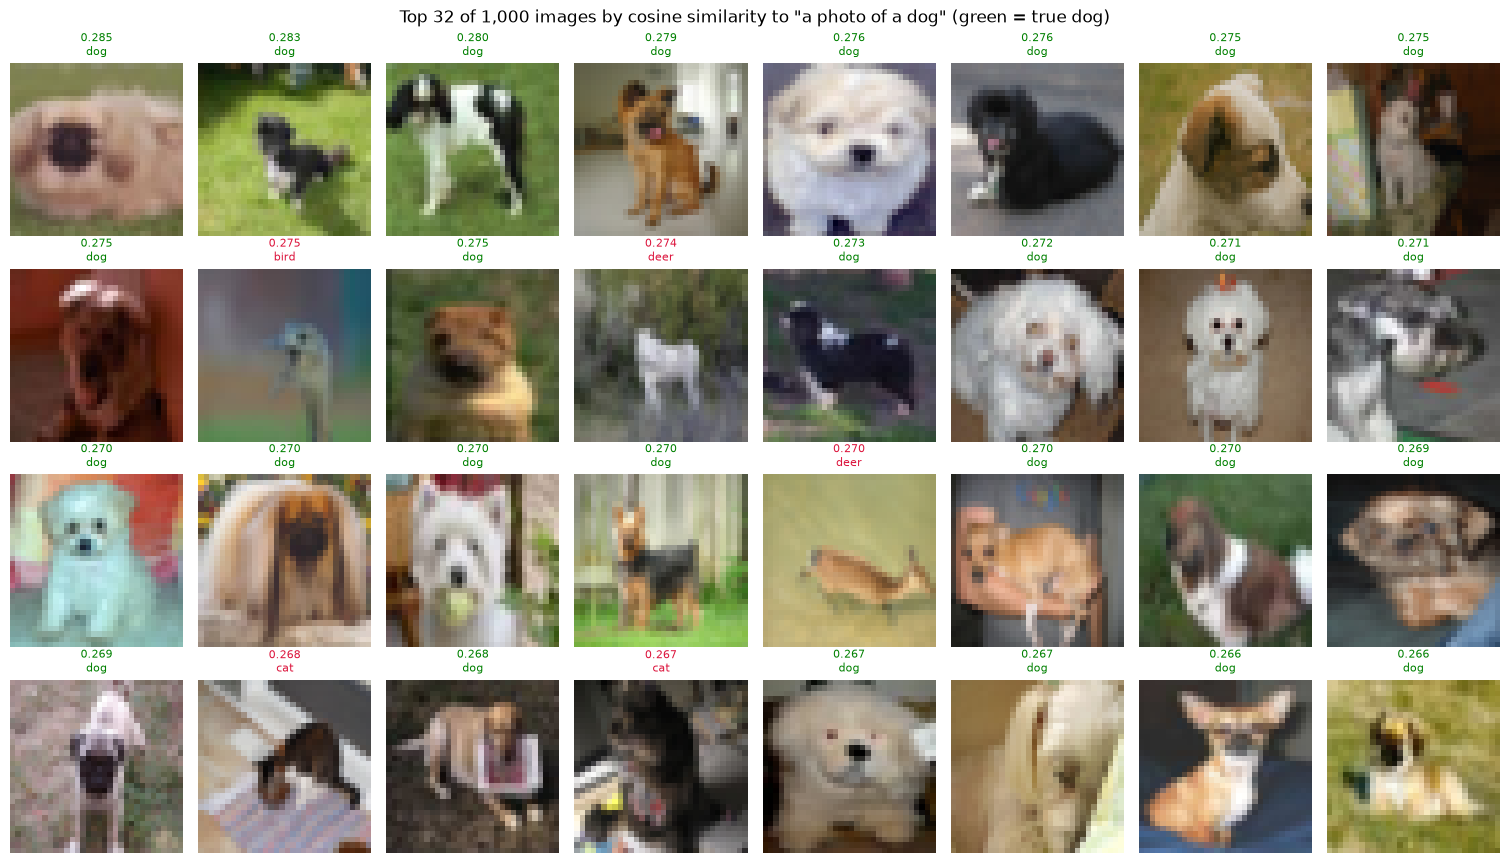

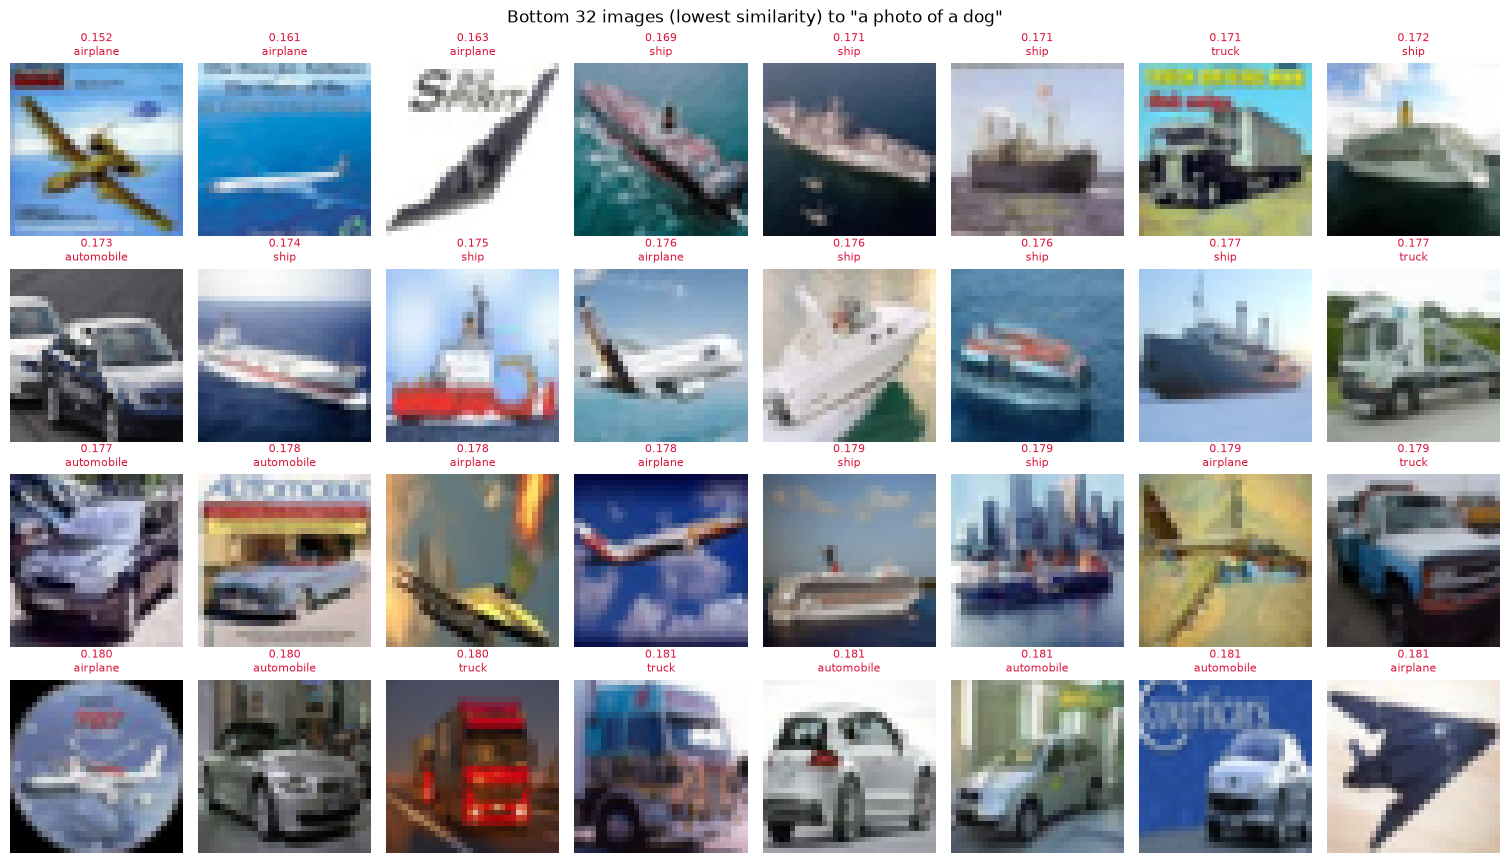

In [7]:
def grid(order, title, fname, ncols=8, nrows=4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*1.9, nrows*2.2))
    for ax, i in zip(axes.ravel(), order[:ncols*nrows]):
        ax.imshow(imgs[i]); ax.axis('off')
        ax.set_title(f'{sims[i]:.3f}\n{classes[y[i]]}', fontsize=8,
                     color='green' if y[i] == TARGET else 'crimson')
    fig.suptitle(title, fontsize=12); plt.tight_layout()
    plt.savefig(f'figures/{fname}', dpi=130, bbox_inches='tight'); plt.show()

grid(rank, f'Top 32 of 1,000 images by cosine similarity to "{CAPTION}" (green = true dog)', 'top32.png')
grid(rank[::-1], f'Bottom 32 images (lowest similarity) to "{CAPTION}"', 'bottom32.png')

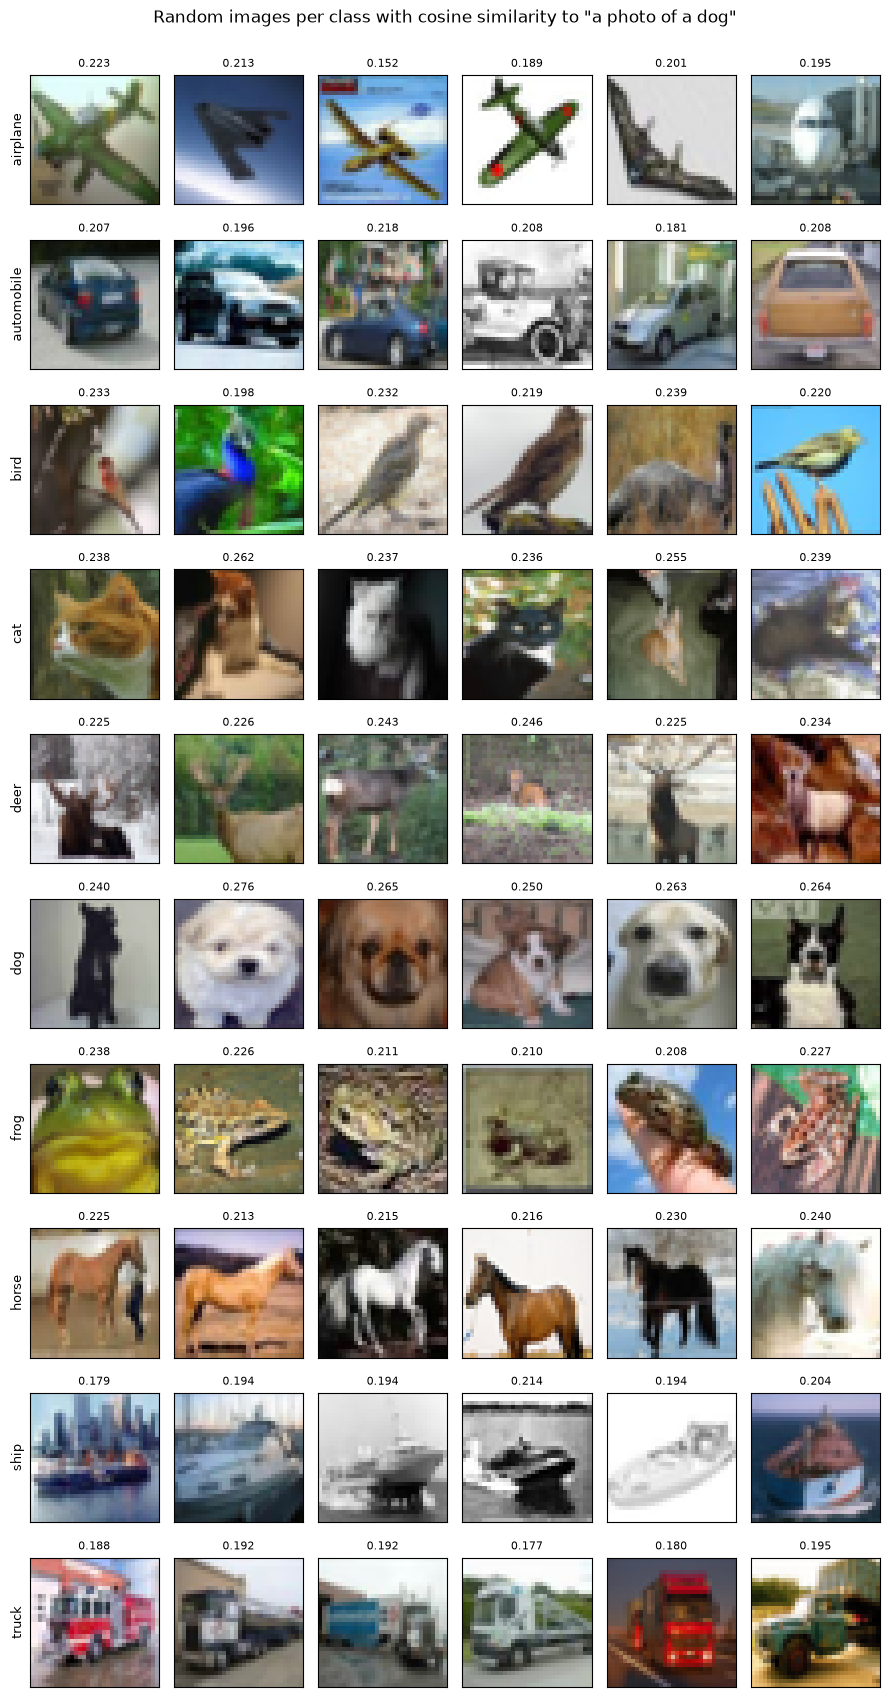

In [8]:
# Mixed view: 6 random images from every class, labeled with score, so each class is represented
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(10, 6, figsize=(9, 17))
for c in range(10):
    pick = rng.choice(np.where(y == c)[0], 6, replace=False)
    for ax, i in zip(axes[c], pick):
        ax.imshow(imgs[i]); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'{sims[i]:.3f}', fontsize=8)
    axes[c, 0].set_ylabel(classes[c], fontsize=9)
fig.suptitle(f'Random images per class with cosine similarity to "{CAPTION}"', y=1.0)
plt.tight_layout(); plt.savefig('figures/per_class_samples.png', dpi=130, bbox_inches='tight'); plt.show()

/var/folders/59/1w_x8dqx59x97rhs_105syh00000gn/T/ipykernel_81633/2194056787.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([sims[y == c] for c in order], tick_labels=[classes[c] for c in order], vert=True)


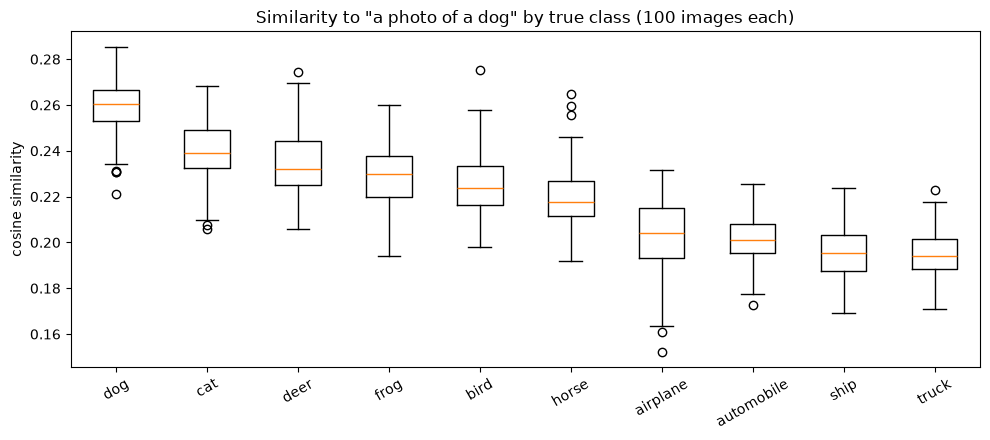

In [9]:
# Score distribution per class
order = sorted(range(10), key=lambda c: -np.median(sims[y == c]))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([sims[y == c] for c in order], tick_labels=[classes[c] for c in order], vert=True)
ax.set_ylabel('cosine similarity'); ax.set_title(f'Similarity to "{CAPTION}" by true class (100 images each)')
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig('figures/score_by_class.png', dpi=130); plt.show()

### Other captions (same 1,000 image embeddings)

The image embeddings are reused, so scoring every class caption costs nothing extra. Each row below is a caption, each column the true image class; the cell is the mean cosine similarity. A good caption should light up its own column.

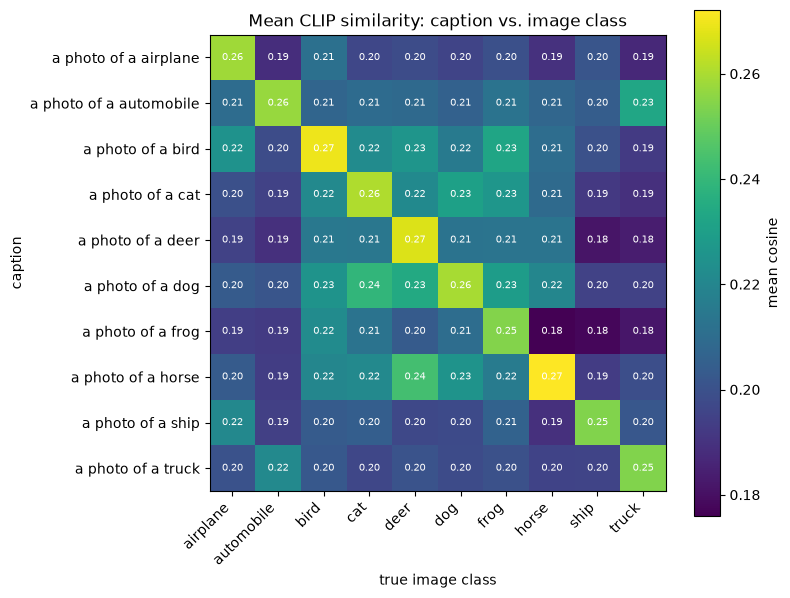

classes where the matching caption has the highest mean similarity: 10 / 10
{'airplane': 0.992, 'automobile': 0.993, 'bird': 0.971, 'cat': 0.962, 'deer': 0.978, 'dog': 0.962, 'frog': 0.958, 'horse': 0.987, 'ship': 0.993, 'truck': 0.983}


In [10]:
caps = [f'a photo of a {c}' for c in classes]
T = embed_text(caps)
M = (T @ img_emb.T).numpy()                               # (10 captions, 1000 images)
heat = np.stack([M[:, y == c].mean(1) for c in range(10)], 1)   # caption x true class
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(heat, cmap='viridis')
ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(caps)
ax.set_xlabel('true image class'); ax.set_ylabel('caption')
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{heat[i,j]:.2f}', ha='center', va='center', fontsize=7, color='w')
plt.colorbar(im, label='mean cosine'); ax.set_title('Mean CLIP similarity: caption vs. image class')
plt.tight_layout(); plt.savefig('figures/caption_class_heatmap.png', dpi=130); plt.show()
diag_best = [int(heat[:, j].argmax() == j) for j in range(10)]
print('classes where the matching caption has the highest mean similarity:', sum(diag_best), '/ 10')
aucs = {classes[c]: float(roc_auc_score((y == c).astype(int), M[c])) for c in range(10)}
print({k: round(v, 3) for k, v in aucs.items()})
results['part1']['heatmap_diag_best'] = sum(diag_best)
results['part1']['auc_by_caption'] = aucs

## 7. Part 2 — zero-shot classification on CIFAR-10

Classify each of the 10,000 test images by the class prompt with the highest cosine similarity. No training or fine-tuning. I compare the single template `a photo of a {class}` with an ensemble of 4 templates (average of normalized text embeddings, then renormalized).

In [11]:
test_imgs = [ds[i][0] for i in range(len(ds))]
ytest = labels_all
t0 = time.time()
test_emb = embed_images(test_imgs)
print('embedded', len(test_imgs), 'test images in', f'{time.time()-t0:.0f}s', tuple(test_emb.shape))

embedded 10000 test images in 1239s (10000, 512)


In [12]:
def class_text_emb(templates):
    embs = []
    for c in classes:
        e = embed_text([t.format(c) for t in templates]).mean(0)
        embs.append(torch.nn.functional.normalize(e, dim=-1))
    return torch.stack(embs)                                   # (10, 512)

TEMPLATES = {
    'single': ['a photo of a {}'],
    'ensemble': ['a photo of a {}', 'a blurry photo of a {}', 'a low resolution photo of a {}', 'a photo of the small {}'],
}
def evaluate(templates):
    pred = (test_emb @ class_text_emb(templates).T).argmax(1).numpy()
    cm = confusion_matrix(ytest, pred, labels=range(10))
    return pred, cm, cm.diagonal() / cm.sum(1)

part2 = {}
for name, tpl in TEMPLATES.items():
    pred, cm, pc = evaluate(tpl)
    acc = float((pred == ytest).mean())
    part2[name] = dict(accuracy=acc, per_class={classes[c]: float(pc[c]) for c in range(10)}, confusion=cm.tolist())
    print(f'{name:9s} overall accuracy = {acc:.4f}')
results['part2'] = part2

single    overall accuracy = 0.8880


ensemble  overall accuracy = 0.8905


      class   single  ensemble
   airplane    0.901     0.907
 automobile    0.976     0.963
       bird    0.888     0.874
        cat    0.860     0.844
       deer    0.765     0.785
        dog    0.884     0.884
       frog    0.774     0.792
      horse    0.976     0.978
       ship    0.955     0.964
      truck    0.901     0.914


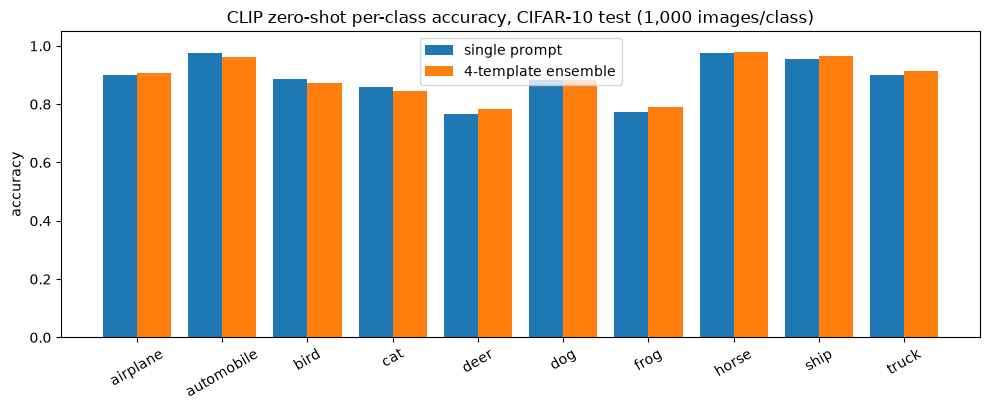

In [13]:
# Per-class accuracy (single template = the main result; ensemble shown for comparison)
print(f'{"class":>11s} {"single":>8s} {"ensemble":>9s}')
for c in classes:
    print(f'{c:>11s} {part2["single"]["per_class"][c]:8.3f} {part2["ensemble"]["per_class"][c]:9.3f}')
fig, ax = plt.subplots(figsize=(10, 4.2))
w = 0.4; x = np.arange(10)
ax.bar(x - w/2, [part2['single']['per_class'][c] for c in classes], w, label='single prompt')
ax.bar(x + w/2, [part2['ensemble']['per_class'][c] for c in classes], w, label='4-template ensemble')
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=30); ax.set_ylabel('accuracy'); ax.set_ylim(0, 1.05)
ax.set_title('CLIP zero-shot per-class accuracy, CIFAR-10 test (1,000 images/class)'); ax.legend()
plt.tight_layout(); plt.savefig('figures/per_class_accuracy.png', dpi=130); plt.show()

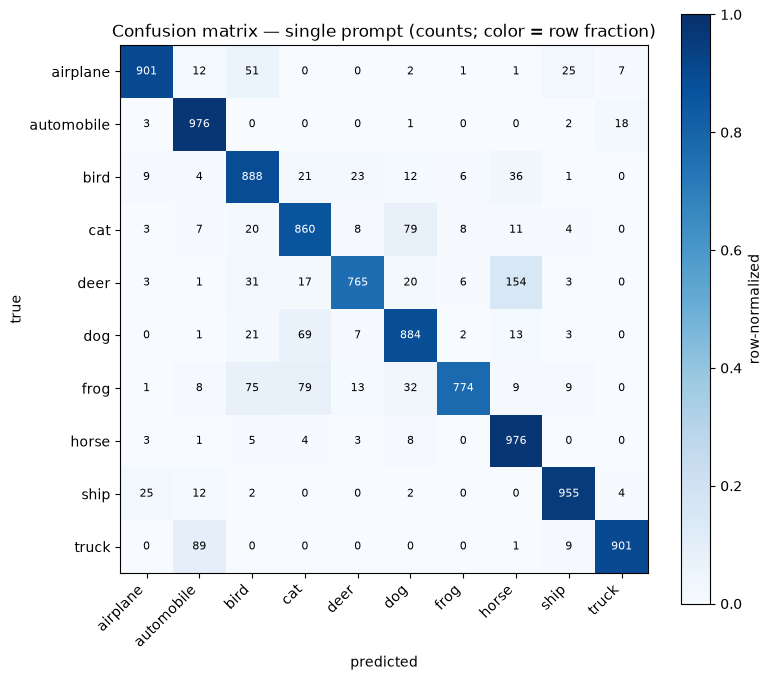

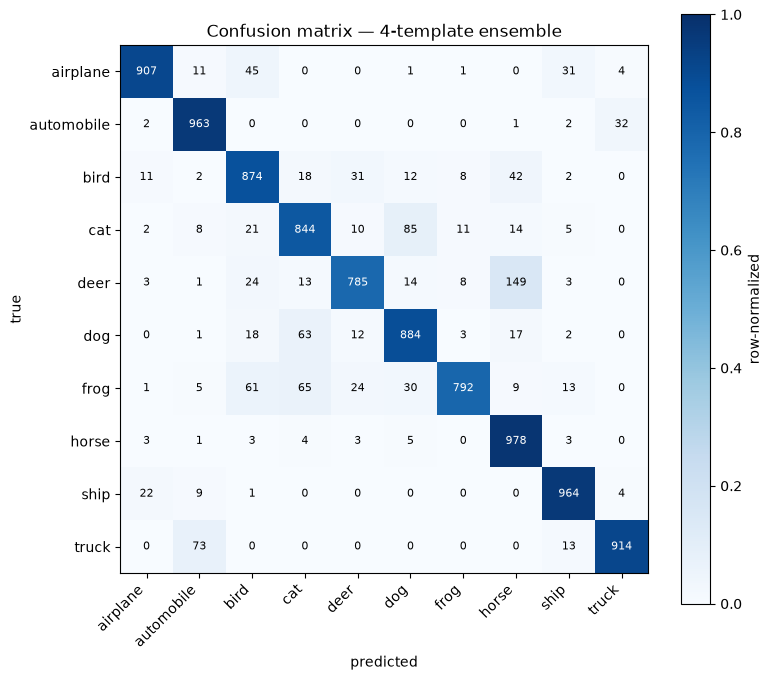

In [14]:
def plot_cm(cm, title, fname):
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_yticks(range(10)); ax.set_yticklabels(classes)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=8,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    plt.colorbar(im, label='row-normalized'); plt.tight_layout()
    plt.savefig(f'figures/{fname}', dpi=130); plt.show()

plot_cm(np.array(part2['single']['confusion']), 'Confusion matrix — single prompt (counts; color = row fraction)', 'confusion_single.png')
plot_cm(np.array(part2['ensemble']['confusion']), 'Confusion matrix — 4-template ensemble', 'confusion_ensemble.png')

In [15]:
# Most common confusions (single prompt)
cm = np.array(part2['single']['confusion']); off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:6], off.shape))[0]
conf = [(classes[i], classes[j], int(off[i, j])) for i, j in top]
for t, p, n in conf: print(f'true {t:>10s} -> predicted {p:<10s} {n} images')
results['part2']['top_confusions'] = conf

# Consistency check: Part-1 subset accuracy should be close to the full-test accuracy
sub_pred = (img_emb @ class_text_emb(TEMPLATES['single']).T).argmax(1).numpy()
print('accuracy on the 1,000-image Part-1 subset:', float((sub_pred == y).mean()))
results['part2']['subset_1000_accuracy'] = float((sub_pred == y).mean())
json.dump(results, open('outputs/results.json', 'w'), indent=2)

true       deer -> predicted horse      154 images
true      truck -> predicted automobile 89 images
true        cat -> predicted dog        79 images
true       frog -> predicted cat        79 images
true       frog -> predicted bird       75 images
true        dog -> predicted cat        69 images
accuracy on the 1,000-image Part-1 subset: 0.904


## Analysis

**Part 1: one caption against 1,000 images.**
- Cosine similarities are all in a narrow band (0.152 to 0.285), which is normal for CLIP: the absolute value is small, and the ranking is what carries the information.
- Dog images score highest on average (mean 0.259), followed by cat (0.239) and deer (0.234). Vehicles are lowest (ship 0.195, truck 0.195, automobile 0.201, airplane 0.203). So CLIP puts the caption closest to the right class and then to other four-legged animals, which is a semantically sensible order.
- As a dog-vs-not-dog detector the score has ROC-AUC 0.962. But only 70 of the 100 top-ranked images are real dogs; the 30 misses include cats, deer and a bird in the top 32 shown above, i.e. the caption cannot fully separate similar animals from dogs at the top of the ranking.
- Across all 10 captions ("a photo of a {class}"), the matching caption has the highest mean similarity for every one of the 10 image classes (heatmap diagonal), and per-caption ROC-AUC is 0.958 to 0.993 (lowest for frog, cat and dog; highest for airplane, automobile, ship).

**Part 2: zero-shot CIFAR-10.**
- Single prompt "a photo of a {class}": **88.8%** overall. 4-template ensemble: **89.05%**, so prompt ensembling helped by only +0.25 points; it helped some classes (frog, deer, truck) and hurt others (automobile, bird, cat), so I treat it as a wash.
- Per-class accuracy (single prompt): automobile 97.6%, horse 97.6%, ship 95.5%, truck 90.1%, airplane 90.1%, bird 88.8%, dog 88.4%, cat 86.0%, frog 77.4%, deer 76.5%.
- Largest confusions: deer predicted as horse (154 images), truck as automobile (89), cat as dog (79), frog as cat (79), frog as bird (75), dog as cat (69). They are visually and semantically close pairs, and at 32x32 upsampled to 224x224 the images are very blurry, which hurts small-animal classes (frog, deer) most.
- The 1,000-image Part 1 subset gives 90.4% with the same prompt vs. 88.8% on the full test set, a gap of 1.6 points that is within sampling noise for 1,000 images (about 1 point standard error), and a reminder that the subset is not an exact stand-in.

**Limitations.** One model (ViT-B/32) and one run (CLIP inference is deterministic; the seed only fixes the random picks in the sample figure), prompts chosen by hand, and CIFAR-10 upsampled from 32x32. I did not test larger CLIP models or tuned prompts; that could change the ranking of the hard classes.